# 2026-06-08 DNA Quantification — Before vs After Concentration (Portelite BDR / Qubit)

Processes the Qubit fluorescence data in
[`../lab_notebook/digitalized/2026-06-08_metagenomic-extraction-dna-concentration-quantification.md`](../lab_notebook/digitalized/2026-06-08_metagenomic-extraction-dna-concentration-quantification.md)
(source pages p.34–p.36).

The 2026-06-08 session re-extracted metagenomic DNA from soil sites **#1, #6, #8, #9**
(small-biomass, 4 lysis tubes pooled per site), then **concentrated** the pooled eluate. Each
site was Qubit-read **twice**:

- **Unconcentrated** — read against **last week's (2026-06-05) 6-point standard curve**.
- **Concentrated** — read against a **new 4-point smaller-volume curve** made this session.

So unlike `0605_quantification.ipynb` (single curve), this notebook builds **two curves + two
converters** and reports a **before/after-concentration** comparison.

> Both reads are now in: unconcentrated against the OLD 6-point curve, concentrated against the
> NEW 4-point curve. A few p.36 digits remain `[TBD]` in the entry (S0/S1/C1/C8/C9), but the
> before/after table is complete.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os

# ---- Tunable assay parameters -------------------------------------------------
DILUTION_FACTOR = 1            # multiply curve-derived conc by this if samples were pre-diluted
VOL_UNCONC_uL = np.nan         # [TBD] eluate volume in the unconcentrated assay (p.35 margin ~390 uL?)
VOL_CONC_uL   = 30.0           # [TBD] concentrated eluate final volume (p.36 margin implies ~30 uL)
DATE = '2026-06-08'
OUTPUT_DIR = 'output'          # figures saved here, named by date + content
os.makedirs(OUTPUT_DIR, exist_ok=True)
# -------------------------------------------------------------------------------

## Section 1 — Two standard curves

`OLD` = the 2026-06-05 6-point curve (reused for the **unconcentrated** reads).
`NEW` = the 2026-06-08 4-point smaller-volume curve (for the **concentrated** reads).

Each curve: subtract the Std-0 blank RFU, fit `RFU_corrected = slope*conc + intercept` by linear
regression, report slope / intercept / R^2.

In [2]:
# Standard series (conc ng/uL, raw green-channel RFU)
standards_old = pd.DataFrame({
    'standard':   ['Std 0 (blank)', 'Std 1', 'Std 3', 'Std 10', 'Std 30', 'Std 100'],
    'conc_ng_uL': [0.0, 1.0, 3.0, 10.0, 30.0, 100.0],
    'rfu':        [127.59, 325.63, 606.82, 1833.66, 5229.49, 16695.43],   # 2026-06-05 (p.31)
})
standards_new = pd.DataFrame({
    'standard':   ['Std 0 (blank)', 'Std 1', 'Std 10', 'Std 30'],
    'conc_ng_uL': [0.0, 1.0, 10.0, 30.0],
    'rfu':        [156.326, 173.90, 316.95, 724.52],   # 2026-06-08 (p.36); some digits [TBD]
})

def fit_curve(df):
    """Blank-subtract and linear-fit a standards table. Returns fit params + the df."""
    df = df.copy()
    blank = df.loc[df['conc_ng_uL'] == 0, 'rfu'].iloc[0]
    df['rfu_corrected'] = df['rfu'] - blank
    slope, intercept = np.polyfit(df['conc_ng_uL'], df['rfu_corrected'], 1)
    fit = slope * df['conc_ng_uL'] + intercept
    ss_res = np.sum((df['rfu_corrected'] - fit) ** 2)
    ss_tot = np.sum((df['rfu_corrected'] - df['rfu_corrected'].mean()) ** 2)
    r2 = 1 - ss_res / ss_tot
    return {'df': df, 'blank': blank, 'slope': slope, 'intercept': intercept,
            'r2': r2, 'max_conc': df['conc_ng_uL'].max()}

OLD = fit_curve(standards_old)
NEW = fit_curve(standards_new)

for name, c in [('OLD 6-point (unconcentrated)', OLD), ('NEW 4-point (concentrated)', NEW)]:
    print(f'{name:32s} blank={c["blank"]:8.2f}  slope={c["slope"]:9.4f}  '
          f'intercept={c["intercept"]:9.4f}  R^2={c["r2"]:.6f}  top={c["max_conc"]:.0f} ng/uL')

OLD 6-point (unconcentrated)     blank=  127.59  slope= 165.6425  intercept=  33.4265  R^2=0.999929  top=100 ng/uL
NEW 4-point (concentrated)       blank=  156.33  slope=  18.9739  intercept=  -7.8849  R^2=0.997129  top=30 ng/uL


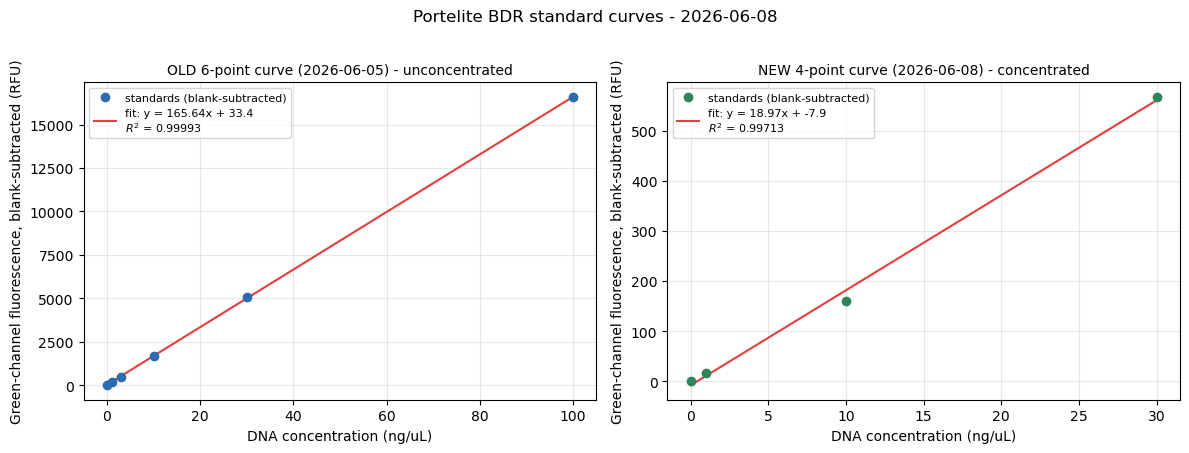

In [3]:
def make_converter(curve):
    """Return a function: raw RFU -> concentration (ng/uL) in the original tube, for this curve."""
    def conv(rfu):
        return (np.asarray(rfu, dtype=float) - curve['blank'] - curve['intercept']) / curve['slope'] * DILUTION_FACTOR
    return conv

rfu_to_conc_old = make_converter(OLD)
rfu_to_conc_new = make_converter(NEW)

# Plot both standard curves side by side
fig, axes = plt.subplots(1, 2, figsize=(12, 4.4))
for ax, (title, c, color) in zip(axes, [
        ('OLD 6-point curve (2026-06-05) - unconcentrated', OLD, '#2b6cb0'),
        ('NEW 4-point curve (2026-06-08) - concentrated', NEW, '#2f855a')]):
    df = c['df']
    ax.scatter(df['conc_ng_uL'], df['rfu_corrected'], color=color, zorder=3,
               label='standards (blank-subtracted)')
    xline = np.linspace(0, c['max_conc'], 100)
    ax.plot(xline, c['slope'] * xline + c['intercept'], color='#e53e3e', lw=1.5,
            label=f"fit: y = {c['slope']:.2f}x + {c['intercept']:.1f}\n$R^2$ = {c['r2']:.5f}")
    ax.set_xlabel('DNA concentration (ng/uL)')
    ax.set_ylabel('Green-channel fluorescence, blank-subtracted (RFU)')
    ax.set_title(title, fontsize=10)
    ax.legend(loc='upper left', fontsize=8)
    ax.grid(alpha=0.3)
fig.suptitle('Portelite BDR standard curves - 2026-06-08', y=1.02)
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, f'{DATE}_standard-curve.png'), dpi=150, bbox_inches='tight')
plt.show()

## Section 2 — Sample concentrations, before vs after

Sites #1, #6, #8, #9. Unconcentrated reads inverted on the OLD curve; concentrated reads on the
NEW curve. `fold_change = conc_concentrated / conc_unconcentrated`.

> Site #1 reads **below the blank on both curves** (unconc 119.87 < OLD blank 127.59; conc 151.67
> < NEW blank 156.33) → ≈ 0 ng/µL before and after, so its fold-change is not meaningful.

In [4]:
SITES = [1, 6, 8, 9]

# Unconcentrated readings (-> OLD curve), from the bench record (sites #1, #6, #8, #9).
UNCONC_RFU = {1: 119.87, 6: 195.94, 8: 3600.46, 9: 1139.16}

# Concentrated readings (-> NEW curve). From p.36 (C1 last digit / C8 / C9 digits [TBD]).
CONC_RFU = {1: 151.67, 6: 216.38, 8: 5655.31, 9: 3197.36}

samples = pd.DataFrame({'site': SITES})
samples['rfu_unconc'] = samples['site'].map(UNCONC_RFU)
samples['rfu_conc']   = samples['site'].map(CONC_RFU)
samples['conc_unconc_ng_uL'] = rfu_to_conc_old(samples['rfu_unconc'])
samples['conc_conc_ng_uL']   = rfu_to_conc_new(samples['rfu_conc'])
samples['fold_change']       = samples['conc_conc_ng_uL'] / samples['conc_unconc_ng_uL']
samples['conc_extrapolated'] = samples['conc_conc_ng_uL'] > NEW['max_conc']

with pd.option_context('display.float_format', lambda v: f'{v:,.2f}'):
    print(samples[['site', 'rfu_unconc', 'conc_unconc_ng_uL', 'rfu_conc',
                   'conc_conc_ng_uL', 'fold_change', 'conc_extrapolated']].to_string(index=False))

 site  rfu_unconc  conc_unconc_ng_uL  rfu_conc  conc_conc_ng_uL  fold_change  conc_extrapolated
    1      119.87              -0.25    151.67             0.17        -0.69              False
    6      195.94               0.21    216.38             3.58        16.98              False
    8    3,600.46              20.76  5,655.31           290.23        13.98               True
    9    1,139.16               5.91  3,197.36           160.69        27.21               True


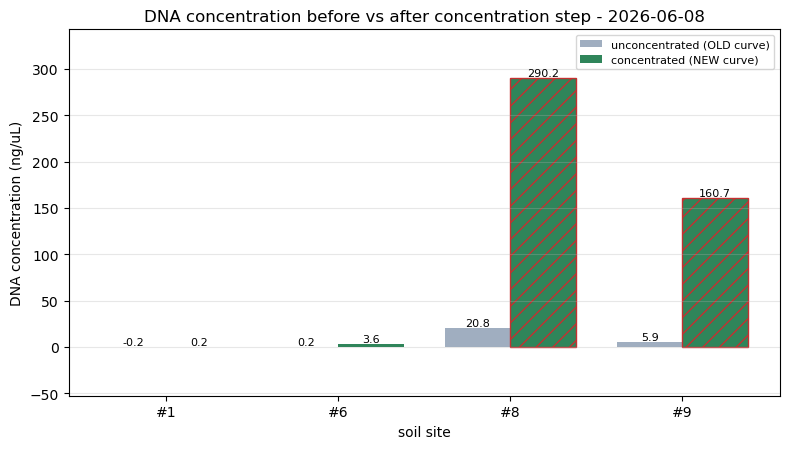

In [5]:
# Before/after concentration bar chart (NaN before-values handled gracefully)
fig, ax = plt.subplots(figsize=(8, 4.6))
x = np.arange(len(samples)); w = 0.38
b1 = ax.bar(x - w/2, samples['conc_unconc_ng_uL'], w, color='#a0aec0',
            label='unconcentrated (OLD curve)')
b2 = ax.bar(x + w/2, samples['conc_conc_ng_uL'], w, color='#2f855a',
            label='concentrated (NEW curve)')
for bar, extrap in zip(b2, samples['conc_extrapolated']):
    if extrap:
        bar.set_hatch('//'); bar.set_edgecolor('#c53030')
for bars in (b1, b2):
    for bar in bars:
        h = bar.get_height()
        if np.isfinite(h):
            ax.text(bar.get_x() + bar.get_width()/2, h, f'{h:.1f}',
                    ha='center', va='bottom', fontsize=8)
ax.set_xticks(x); ax.set_xticklabels([f'#{s}' for s in samples['site']])
ax.set_xlabel('soil site'); ax.set_ylabel('DNA concentration (ng/uL)')
ax.set_title('DNA concentration before vs after concentration step - 2026-06-08')
ax.legend(fontsize=8); ax.grid(axis='y', alpha=0.3); ax.margins(y=0.18)
if samples['conc_unconc_ng_uL'].isna().all():
    ax.text(0.5, 0.92, 'unconcentrated readings [TBD] - see notebook header',
            transform=ax.transAxes, ha='center', color='#c53030', fontsize=9)
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, f'{DATE}_concentration-before-after.png'),
            dpi=150, bbox_inches='tight')
plt.show()

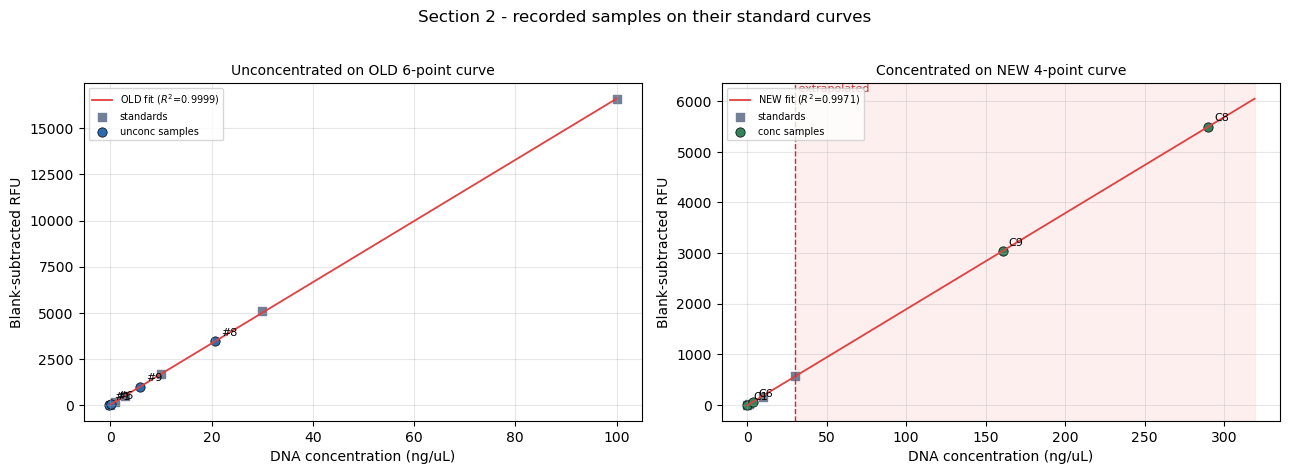

In [6]:
# Place each sample on its curve: unconcentrated on OLD, concentrated on NEW
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))

# Left: unconcentrated on OLD curve
ax = axes[0]; c = OLD
finite = samples['rfu_unconc'].notna()
xmax = max((samples.loc[finite, 'conc_unconc_ng_uL'].max() if finite.any() else 0) * 1.1, c['max_conc'])
xs = np.linspace(0, xmax, 100)
ax.plot(xs, c['slope']*xs + c['intercept'], color='#e53e3e', lw=1.3, label=f"OLD fit ($R^2$={c['r2']:.4f})")
ax.scatter(c['df']['conc_ng_uL'], c['df']['rfu_corrected'], color='#718096', marker='s', s=35, label='standards')
if finite.any():
    ax.scatter(samples.loc[finite, 'conc_unconc_ng_uL'], samples.loc[finite, 'rfu_unconc'] - c['blank'],
               color='#2b6cb0', s=45, edgecolor='black', lw=0.5, label='unconc samples')
    for _, r in samples[finite].iterrows():
        ax.annotate(f"#{int(r['site'])}", (r['conc_unconc_ng_uL'], r['rfu_unconc'] - c['blank']),
                    textcoords='offset points', xytext=(4, 4), fontsize=8)
else:
    ax.text(0.5, 0.5, 'unconcentrated readings [TBD]', transform=ax.transAxes,
            ha='center', color='#c53030', fontsize=10)
ax.set_title('Unconcentrated on OLD 6-point curve', fontsize=10)
ax.set_xlabel('DNA concentration (ng/uL)'); ax.set_ylabel('Blank-subtracted RFU')
ax.legend(fontsize=7, loc='upper left'); ax.grid(alpha=0.3)

# Right: concentrated on NEW curve
ax = axes[1]; c = NEW
xmax = max(samples['conc_conc_ng_uL'].max()*1.1, c['max_conc'])
xs = np.linspace(0, xmax, 100)
ax.plot(xs, c['slope']*xs + c['intercept'], color='#e53e3e', lw=1.3, label=f"NEW fit ($R^2$={c['r2']:.4f})")
ax.scatter(c['df']['conc_ng_uL'], c['df']['rfu_corrected'], color='#718096', marker='s', s=35, label='standards')
ax.scatter(samples['conc_conc_ng_uL'], samples['rfu_conc'] - c['blank'],
           color='#2f855a', s=45, edgecolor='black', lw=0.5, label='conc samples')
for _, r in samples.iterrows():
    ax.annotate(f"C{int(r['site'])}", (r['conc_conc_ng_uL'], r['rfu_conc'] - c['blank']),
                textcoords='offset points', xytext=(4, 4), fontsize=8)
if xmax > c['max_conc']:
    ax.axvspan(c['max_conc'], xmax, color='#fed7d7', alpha=0.4, zorder=0)
    ax.axvline(c['max_conc'], color='#c53030', ls='--', lw=1)
    ax.text(c['max_conc'], ax.get_ylim()[1], ' extrapolated', color='#c53030', fontsize=8, va='top')
ax.set_title('Concentrated on NEW 4-point curve', fontsize=10)
ax.set_xlabel('DNA concentration (ng/uL)'); ax.set_ylabel('Blank-subtracted RFU')
ax.legend(fontsize=7, loc='upper left'); ax.grid(alpha=0.3)

fig.suptitle('Section 2 - recorded samples on their standard curves', y=1.02)
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, f'{DATE}_samples-on-standard-curve.png'), dpi=150, bbox_inches='tight')
plt.show()

## Section 3 — DNA mass per tube

`mass = concentration (ng/uL) x remaining volume (uL)`, in ug. Concentrated final volume
`VOL_CONC_uL` is `[TBD]` (p.36 margin implies ~30 uL); unconcentrated volume is `[TBD]`, so the
unconcentrated mass column stays NaN until both are confirmed.

In [7]:
samples['mass_conc_ug']   = samples['conc_conc_ng_uL'] * VOL_CONC_uL / 1000.0
samples['mass_unconc_ug'] = samples['conc_unconc_ng_uL'] * VOL_UNCONC_uL / 1000.0
with pd.option_context('display.float_format', lambda v: f'{v:,.3f}'):
    print(samples[['site', 'conc_conc_ng_uL', 'mass_conc_ug',
                   'conc_unconc_ng_uL', 'mass_unconc_ug']].to_string(index=False))
print(f"\nConcentrated total recoverable DNA: {np.nansum(samples['mass_conc_ug']):,.3f} ug "
      f"(at VOL_CONC_uL={VOL_CONC_uL} uL/tube, which is [TBD])")

 site  conc_conc_ng_uL  mass_conc_ug  conc_unconc_ng_uL  mass_unconc_ug
    1            0.170         0.005             -0.248             NaN
    6            3.581         0.107              0.211             NaN
    8          290.233         8.707             20.764             NaN
    9          160.690         4.821              5.905             NaN

Concentrated total recoverable DNA: 13.640 ug (at VOL_CONC_uL=30.0 uL/tube, which is [TBD])


## Section 4 — Sequencing submission (2026-06-08) + dilution

Samples sent for sequencing on 2026-06-08:
- **Metagenomes:** sites **#8, #9** — the *concentrated* DNA from this notebook (NEW curve).
- **Bacterial genomes:** **9-2-1, 9-6-2, 10-10-2** — concentrations from
  [`0605_quantification.ipynb`](0605_quantification.ipynb) Set A (2026-06-05).

- **Metagenomes (#8, #9): diluted** — **38 uL DNA + 50 uL kit buffer = 88 uL** (factor 38/88).
  The 38 uL is the concentration-process eluate (40 uL curated - 2 uL for quant = 38 uL).
- **Bacterial genomes: NOT diluted** — submitted at their 2026-06-05 extraction concentration;
  volume per the 2026-06-05 bacteria-extraction record (~90 uL eluate remaining). `[TBD: exact
  submitted volume if less than the full ~90 uL.]`

> Pre-dilution concentrations are **extrapolated** above their curve's top standard for all five
> samples (metagenomes above the NEW Std 30; the three bacterial above the 0605 Std 100) — the
> submitted values inherit that caveat.

In [8]:
# Sequencing submission 2026-06-08.
# Metagenomes: diluted 38 uL DNA + 50 uL kit buffer = 88 uL (40 curated - 2 quant = 38).
# Bacterial genomes: NOT diluted -- submitted at 2026-06-05 conc; volume ~90 uL (0605 margin).
META_INPUT_uL  = 38.0
META_BUFFER_uL = 50.0
BACT_VOL_uL    = 90.0     # [TBD] exact submitted volume; ~90 uL per the 2026-06-05 bacteria note

conc_by_site = dict(zip(samples['site'], samples['conc_conc_ng_uL']))   # concentrated metagenomes
extrap_by_site = dict(zip(samples['site'], samples['conc_extrapolated']))

# (sample, type, diluted, conc_predil, input_uL, buffer_uL, predil_extrapolated)
seq = pd.DataFrame([
    ('metagenome site #8', 'metagenome',      True,  conc_by_site[8], META_INPUT_uL, META_BUFFER_uL, extrap_by_site[8]),
    ('metagenome site #9', 'metagenome',      True,  conc_by_site[9], META_INPUT_uL, META_BUFFER_uL, extrap_by_site[9]),
    ('9-2-1',              'bacterial genome', False, 139.29, BACT_VOL_uL, 0.0, True),   # 0605; >100 extrap
    ('9-6-2',              'bacterial genome', False, 194.53, BACT_VOL_uL, 0.0, True),   # 0605; >100 extrap
    ('10-10-2',           'bacterial genome', False, 140.44, BACT_VOL_uL, 0.0, True),   # 0605; >100 extrap
], columns=['sample', 'type', 'diluted', 'conc_predil_ng_uL', 'input_uL', 'buffer_uL', 'predil_extrapolated'])

seq['final_vol_uL']      = seq['input_uL'] + seq['buffer_uL']
seq['conc_final_ng_uL']  = seq['conc_predil_ng_uL'] * seq['input_uL'] / seq['final_vol_uL']
seq['mass_submitted_ug'] = seq['conc_predil_ng_uL'] * seq['input_uL'] / 1000.0

with pd.option_context('display.float_format', lambda v: f'{v:,.2f}'):
    print(seq[['sample', 'type', 'diluted', 'conc_predil_ng_uL', 'input_uL', 'buffer_uL',
               'final_vol_uL', 'conc_final_ng_uL', 'mass_submitted_ug',
               'predil_extrapolated']].to_string(index=False))

            sample             type  diluted  conc_predil_ng_uL  input_uL  buffer_uL  final_vol_uL  conc_final_ng_uL  mass_submitted_ug  predil_extrapolated
metagenome site #8       metagenome     True             290.23     38.00      50.00         88.00            125.33              11.03                 True
metagenome site #9       metagenome     True             160.69     38.00      50.00         88.00             69.39               6.11                 True
             9-2-1 bacterial genome    False             139.29     90.00       0.00         90.00            139.29              12.54                 True
             9-6-2 bacterial genome    False             194.53     90.00       0.00         90.00            194.53              17.51                 True
           10-10-2 bacterial genome    False             140.44     90.00       0.00         90.00            140.44              12.64                 True


## Readout

- **Concentrated set (NEW curve):** sites **#8 and #9** read far above the 30 ng/uL top standard
  (C8 ~ 5,655 RFU, C9 ~ 3,197 RFU) -> heavily **extrapolated**; interpret with caution or
  re-dilute against a higher standard. Sites **#1 and #6** sit near the low standards
  (C6 just above). **C1 reads *below* the Std-0 blank** (151.67 < 156.33 RFU) -> ~ 0 ng/uL,
  surprising for a supposedly *concentrated* sample -- flagged in the entry as "expected (no
  recoverable DNA at site #1), or a transcription slip on C1 / S0?" [TBD]. Site #1 also reads
  below the blank *unconcentrated* (119.87 < 127.59), consistent with simply having ~no DNA.
- **Before/after concentration recovery (fold-change):** sites **#6 ~17x, #8 ~14x, #9 ~27x** —
  the concentration step lifted the dilute eluates into a measurable range. Site **#1 ~0 ng/uL
  both before and after** (no recoverable DNA).
- **Sequencing submission (Section 4):** metagenomes #8/#9 (diluted) + bacterial 9-2-1/9-6-2/
  10-10-2 (undiluted) sent 2026-06-08.